In [5]:
import os

print(os.listdir('/content'))

['.config', 'sample_data']


In [6]:
from google.colab import files

uploaded = files.upload()

Saving multiple_linear_regression_dataset.csv to multiple_linear_regression_dataset.csv


In [7]:
df = pd.read_csv('multiple_linear_regression_dataset.csv')

print(df.head())


   age  experience  income
0   25           1   30450
1   30           3   35670
2   47           2   31580
3   32           5   40130
4   43          10   47830


In [8]:
print(df.columns.tolist())
print(df.shape)


['age', 'experience', 'income']
(20, 3)


In [9]:
# Simple Linear Regression
X_simple = df[["experience"]]

# Multiple Linear Regression
X_multiple = df[["age", "experience"]]

# Dependent variable
y = df["income"]

print("Simple Regression Input:")
print(X_simple.head())

print("\nMultiple Regression Input:")
print(X_multiple.head())

print("\nOutput Variable:")
print(y.head())


Simple Regression Input:
   experience
0           1
1           3
2           2
3           5
4          10

Multiple Regression Input:
   age  experience
0   25           1
1   30           3
2   47           2
3   32           5
4   43          10

Output Variable:
0    30450
1    35670
2    31580
3    40130
4    47830
Name: income, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

# Simple Linear Regression split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

# Multiple Linear Regression split
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multiple, y, test_size=0.2, random_state=42
)

print("Simple Regression:")
print("Training samples:", len(X_train_s))
print("Testing samples:", len(X_test_s))

print("\nMultiple Regression:")
print("Training samples:", len(X_train_m))
print("Testing samples:", len(X_test_m))


Simple Regression:
Training samples: 16
Testing samples: 4

Multiple Regression:
Training samples: 16
Testing samples: 4


In [11]:
# Create Linear Regression model
simple_model = LinearRegression()

# Train the model
simple_model.fit(X_train_s, y_train_s)

# Predict income for test data
simple_predictions = simple_model.predict(X_test_s)

print("Actual Income:")
print(y_test_s.values)

print("\nPredicted Income:")
print(simple_predictions)

Actual Income:
[30450 30870 38900 35670]

Predicted Income:
[29997.58795242 29997.58795242 40248.03087826 34097.76512275]


In [12]:
print("Intercept:", simple_model.intercept_)

print("Coefficient:", simple_model.coef_[0])

Intercept: 27947.499367248794
Coefficient: 2050.0885851683124


In [13]:
print("R2 Score:", r2_score(y_test_s, simple_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test_s, simple_predictions)
))

R2 Score: 0.8931830506174759
RMSE: 1146.1772550018552


In [14]:
# Create Multiple Linear Regression model
multiple_model = LinearRegression()

# Train the model
multiple_model.fit(X_train_m, y_train_m)

# Make predictions
multiple_predictions = multiple_model.predict(X_test_m)

print("Actual Income:")
print(y_test_m.values)

print("\nPredicted Income:")
print(multiple_predictions)

Actual Income:
[30450 30870 38900 35670]

Predicted Income:
[31093.38107376 31295.49954076 40250.46080162 34897.6958918 ]


In [15]:
print("Intercept:", multiple_model.intercept_)

print("Coefficients:", multiple_model.coef_)

print("Age Coefficient:", multiple_model.coef_[0])

print("Experience Coefficient:", multiple_model.coef_[1])

Intercept: 31465.056418503933
Coefficients: [-101.0592335  2154.80549277]
Age Coefficient: -101.05923350088742
Experience Coefficient: 2154.8054927746475


In [16]:
print("R2 Score:", r2_score(y_test_m, multiple_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test_m, multiple_predictions)
))

R2 Score: 0.9387098237077887
RMSE: 868.2147023481314


In [17]:
# New observation for Simple Linear Regression
new_person_simple = pd.DataFrame({
    "experience": [5]
})

# New observation for Multiple Linear Regression
new_person_multiple = pd.DataFrame({
    "age": [30],
    "experience": [5]
})

print("Predicted Income using Simple Regression:",
      simple_model.predict(new_person_simple)[0])

print("Predicted Income using Multiple Regression:",
      multiple_model.predict(new_person_multiple)[0])

Predicted Income using Simple Regression: 38197.94229309035
Predicted Income using Multiple Regression: 39207.30687735055


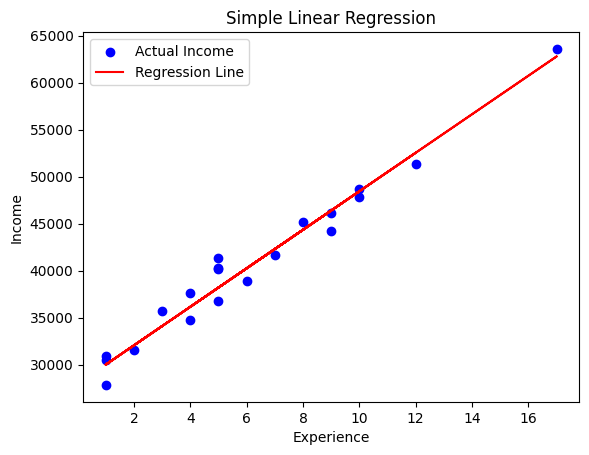

In [18]:
plt.scatter(
    df["experience"],
    df["income"],
    color="blue",
    label="Actual Income"
)

plt.plot(
    df["experience"],
    simple_model.predict(X_simple),
    color="red",
    label="Regression Line"
)

plt.xlabel("Experience")
plt.ylabel("Income")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()